# V06: DNS edits and input validation

Validate scoped add/edit/delete/cancel behavior and record input-validation outcomes.

[Choose another use case](README.md). This notebook is an unexecuted sample, not a live validation report.


## Advanced DNS objective and coverage limits

**Why run it:** Demonstrate that users can maintain Advanced DNS entries, reopen saved configuration, reject malformed input and cancel an unsaved change. A successful data read does not validate those management operations.

**Prerequisite:** A/B must be resolvable from the service environment and suitable for explicit-entry provisioning; customer-only private resolution does not qualify. Keep an unresolved name only as a deliberate negative test.

**Current scope:** The notebook checks supplied add/edit/delete/cancel snapshots and input-validation observations. Exercise the supported workspace creation and editing flows separately where available. Keep unrelated DNS and SCAN entries intact. The current procedure tests Advanced DNS entries; preserving a SCAN snapshot is not a functional SCAN proxy test.

For each saved operation, capture both its operation result and reopened settings. For cancellation and rejected input, capture the unchanged baseline. Record duplicate/normalization and partial-provisioning behavior as observed; do not assume undocumented atomic rollback. For runtime effects, pair this case with V01–V04 or V07. Internal reconciliation, mapping ownership/cleanup, rollout flags and telemetry require separate engineering validation.


## DNS resolution path

Advanced DNS explicit entries and default private DNS proxy resolution serve different purposes. Determine the hostname's resolution path before editing the workspace.

| Mechanism | Resolution and traffic behavior | What to configure or verify |
| --- | --- | --- |
| Explicit Advanced DNS entry | Provisioning resolves the supplied public hostname from the service environment and installs an explicit mapping. The runtime DNS answer directs application traffic through the workspace private connection into the customer VCN. | Use a service-resolvable hostname requiring customer-network routing, then verify provisioning, saved state, workload DNS and the authenticated operation. A customer-VM lookup alone does not establish service-side resolvability. |
| Default private DNS proxy path | A private ADB hostname that the service resolver cannot resolve is handled through the private-endpoint DNS proxy and customer DNS context. | Verify customer DNS, private routes, listener security and the private descriptor. Do not add the private hostname solely because it is private. |
| Regional service-zone allowance | A regional service-domain policy permits covered zones in the applicable context. | Verify the deployment's eligibility and endpoint. This is neither an automatically inserted workspace entry nor proof that the private DNS proxy supplied the answer. |

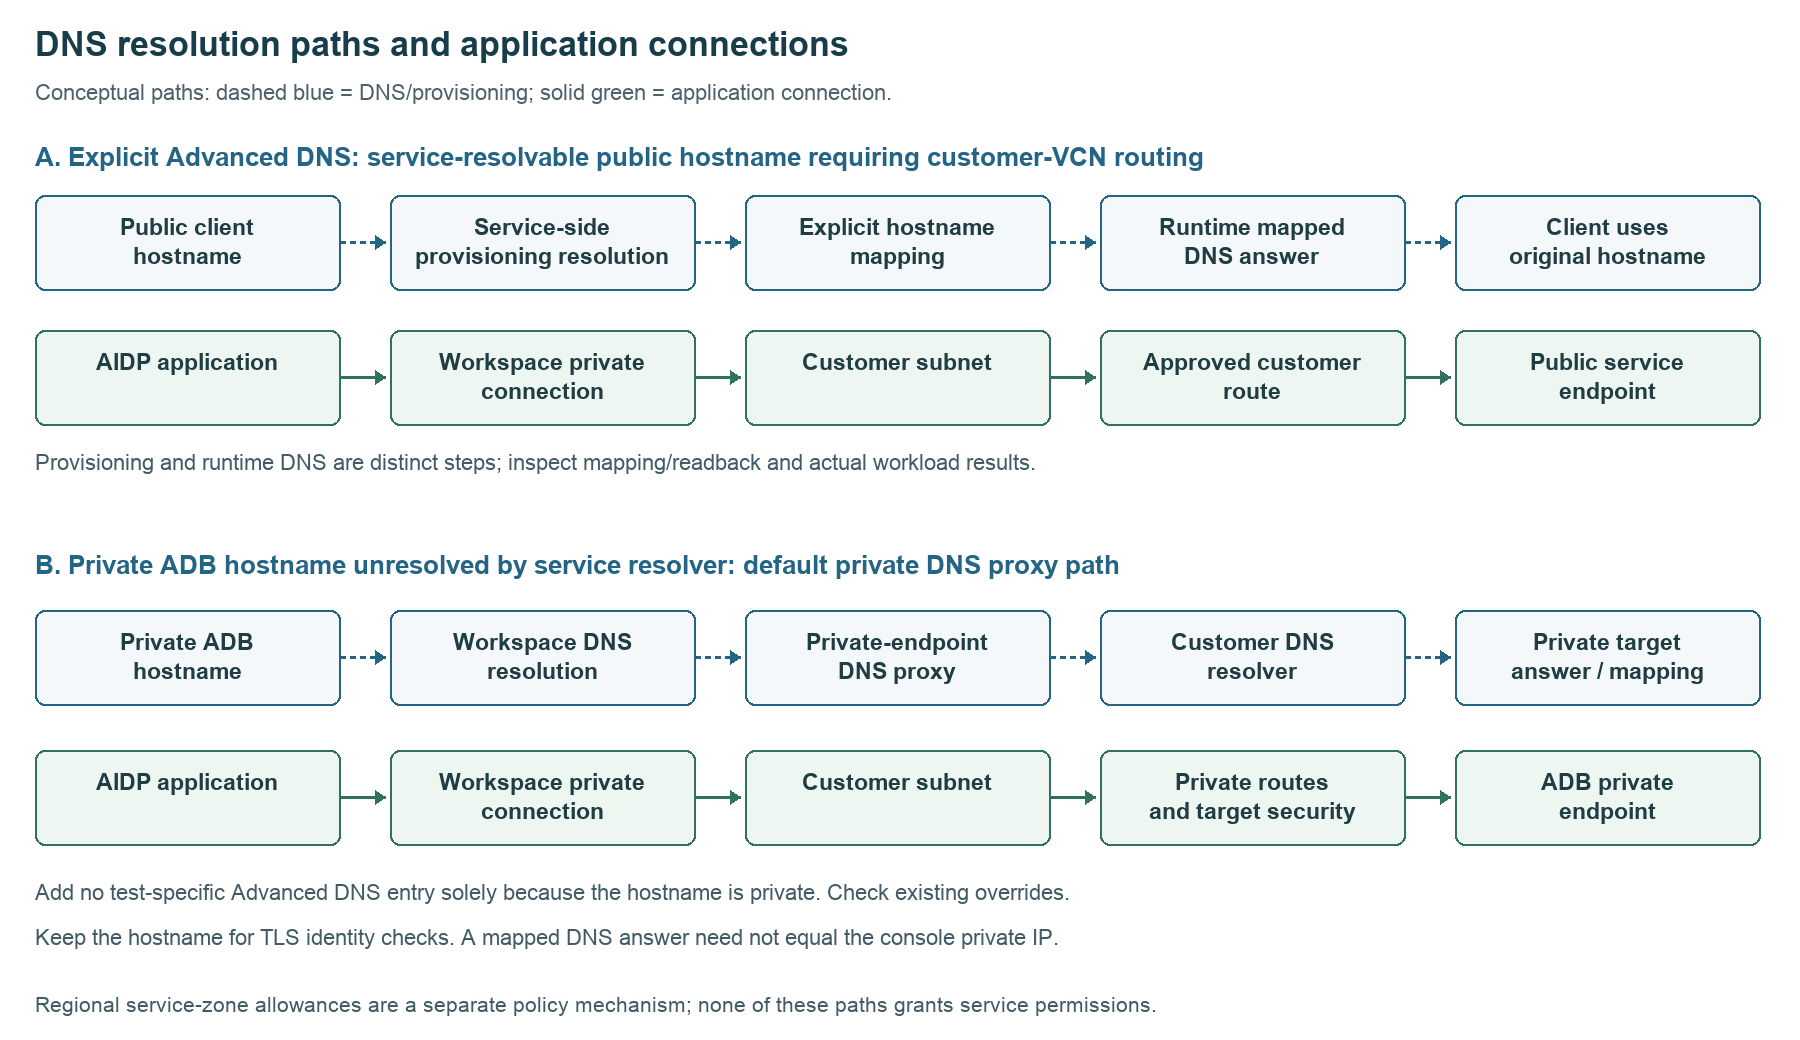

Dashed blue arrows describe DNS/provisioning relationships; solid green arrows show application connections. The diagram is conceptual, not a packet trace. An address returned inside AIDP can be a service-managed mapping and need not equal the private address in the destination console. Keep using the original hostname for TLS server identity checks.

**Before testing:** record the complete DNS/SCAN list, endpoint type, existing overrides and effective client configuration. A successful query alone does not identify the resolution mechanism. Do not delete a shared override to create a clean baseline. Use an approved clean test workspace or mark the default-path claim **INCOMPLETE** when provenance cannot be established.

For V04, first test the private endpoint without adding a test-specific Advanced DNS entry. For V01–V03, V06 and V07, explicit-entry tests require service-resolvable hostnames; private-only names are unsuitable for demonstrating that provisioning mechanism. An unresolved owned name can remain a deliberately negative V06 test.

The [public workspace guide](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html) lists broad private-network scenarios; endpoint type and deployed resolver behavior determine whether an explicit entry is necessary. The [ADB private endpoint guide](https://docs.oracle.com/en/cloud/paas/autonomous-database/serverless/adbsb/private-endpoints-autonomous.html) describes the destination's private access setup. Confirm your deployment's behavior with the administrator and retain independent evidence for the resolution path you claim.


## Network setup

Complete and verify these prerequisites with your network/service administrator before the workload comparison. The notebook does not create routes, change policies, configure DNS, or start compute.

| Area | Required setup and verification |
| --- | --- |
| Owned endpoints | Prepare two owned disposable hostnames A/B that are resolvable from the service environment for explicit Advanced DNS provisioning and an approved existing route to their small fixtures. For an optional partial-provisioning observation, use an owned deliberately unresolved name U. |
| Route and security | Verify A/B are reachable through the workspace's existing customer path and permitted ports. DNS edits do not create routes, gateways or authorization. Keep those controls fixed during the comparison. |
| Workspace editing | Capture the complete DNS list and SCAN settings first. Follow the deployment's edit prerequisites; current public documentation says most network changes require stopped compute. Do not stop another user's resource to perform this sample. |
| Input behavior | Use the FQDN field's published format and current UI validation. Record duplicate/normalization and partially failed-request behavior from actual readback rather than assuming atomic rollback or a universal normalization rule. |


### Example network topology

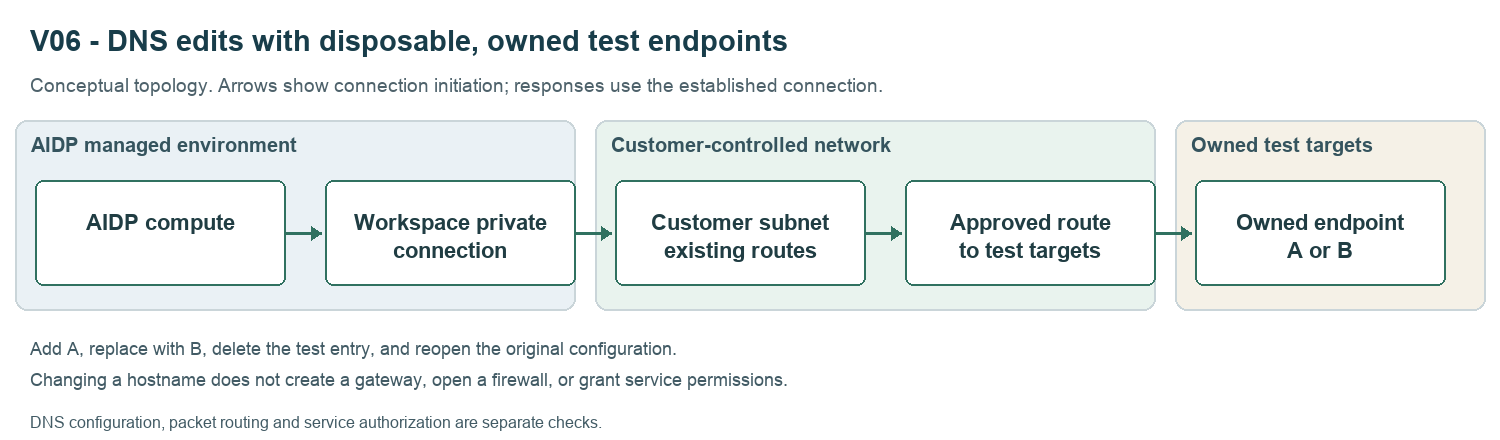

The diagram is illustrative; it does not prove the route taken by a request.


## IAM and network examples

Preparation templates only: replace every angle-bracket placeholder privately. An administrator prepares the approved resources; this notebook applies no policies or network changes.

### Separate operator, service and runtime permissions

The workspace operator needs access to the existing AIDP instance and the appropriate Workbench role/permissions to edit that workspace. Example OCI policies for an identity-domain group are:

```text
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to use ai-data-platforms in compartment <AIDP_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect vcns in compartment <VCN_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect subnets in compartment <SUBNET_COMPARTMENT>
Allow group <IDENTITY_DOMAIN>/<WORKSPACE_OPERATORS> to inspect network-security-groups in compartment <NSG_COMPARTMENT>
```

These statements allow instance access and network selection; they do not grant Workbench workspace-edit privileges, create infrastructure or authorize reads from data sources. Use the existing approved Workbench role. Policies belong in the relevant compartment or an ancestor with authority over that scope.

The platform also needs its private-network service permissions. The following adapts the documented AIDP network statements to explicit resource compartments and one instance:

```text
Allow any-user to manage vnics in compartment <VNIC_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use subnets in compartment <SUBNET_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
Allow any-user to use network-security-groups in compartment <NSG_COMPARTMENT> where all {request.principal.type='<AIDP_PRINCIPAL_TYPE>', request.principal.id='<AIDP_INSTANCE_ID>'}
```

Select the actual instance principal type (`aidataplatform` or the applicable legacy type), instance ID and placement compartments with your administrator. Retain the other existing service setup policies; this is not a full tenancy bootstrap. The runtime reading data can use a different identity from the operator or AIDP service: establish the connector's effective signer before choosing its policy subject.

Sources: [AIDP IAM policies](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/iam-policies-oracle-ai-data-platform.html), [AIDP workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html), [IAM policy scope](https://docs.oracle.com/en-us/iaas/Content/Security/Reference/iam_security_topic-IAM_Security_Policies.htm).

### Platform network baseline

The current workspace guide requires ingress from the customer VCN address range to all destination ports for private-network data access. An example baseline rule is **ingress; source CIDR `<CUSTOMER_VCN_CIDR>`; all protocols/ports; stateful**, in the security control selected for that workspace topology. Have the administrator reconcile this platform prerequisite with the approved design. The target-specific examples below are additional destination controls, not a replacement for platform rules. Do not use an internet-wide ingress rule.

Retain working DNS resolver access. With custom resolvers, permit UDP and TCP 53 to the approved resolver and configure forwarding/resolution in the customer network. Explicit Advanced DNS provisioning requires service-side resolvability; a successful customer-only lookup does not establish that prerequisite. Private ADB names unresolved by the service resolver use the default private DNS proxy/customer resolver path. Do not add them solely because they are private. Advanced DNS does not create a customer DNS zone, resolver endpoint, route, NAT gateway, service gateway or database listener. Use stateful connection rules in these examples; stateless designs need explicit return rules. Security lists and NSGs are additive, so check all applicable rules.

Source: [OCI security rules](https://docs.oracle.com/en-us/iaas/Content/Network/Concepts/securityrules.htm).

Use the shared workspace operator permissions and existing approved workspace-edit role. Reuse owned disposable A/B public endpoints that resolve from the service environment and their existing route, listener rule and authenticated reader. For example, if A/B are in-region Object Storage endpoints, retain the V02 service route and bucket read policy; for public endpoints, retain the V01/V03 approved egress pattern.

An optional unresolved U is an owned test name with no usable resolution, not a request to create a public zone or remove a production record. No extra IAM grant to create DNS zones, change resolver settings or administer gateways is required just to edit Advanced DNS entries. Full baseline snapshots include unrelated DNS/SCAN settings; do not broaden their policies during input tests.

### Supporting pattern: V02

### Runtime policy with source restriction

For a connector authenticated as a user in the named group, a fixture read can use:

```text
Allow group <IDENTITY_DOMAIN>/<FIXTURE_READERS> to read objects in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
Allow group <IDENTITY_DOMAIN>/<FIXTURE_READERS> to read buckets in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
```

For a connector using a verified resource-principal dynamic group, use that subject instead, for example:

```text
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read objects in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
Allow dynamic-group <RUNTIME_DYNAMIC_GROUP> to read buckets in compartment <DATA_COMPARTMENT> where all {target.bucket.name='<TEST_BUCKET>', request.networkSource.name='<CUSTOMER_NETWORK_SOURCE>'}
```

Choose the subject matching the actual signer; do not grant both variants by default. An existing dynamic group must match that resource; these samples do not define a generic AIDP matching rule. Reading objects includes listing objects in the named bucket. No object write privilege is needed. If the chosen connector separately resolves the namespace, verify its namespace-read permission under its existing setup.

Create the Network Source in the tenancy home region with a **VCN entry** containing `<CUSTOMER_VCN_ID>` and `<WORKSPACE_SUBNET_CIDR>`. This is the allowed source network, not the translated destination address from a DNS answer. Keep the restriction unchanged during the comparison. OCI policies are additive: another unconditional allow for the same operation can invalidate this test; review effective grants before claiming a source restriction was enforced. Do not apply this example to the tenancy's console sign-in restriction.

### Route and security example

| Control | Example |
| --- | --- |
| Service gateway | Enable the supported Object Storage service label for `<WORKSPACE_REGION>`. |
| Subnet route | Destination type **Service**, destination the regional Object Storage service CIDR label, target `<SERVICE_GATEWAY_ID>`. |
| Egress | Destination type **Service**, same regional service label, stateful TCP 443. Preserve platform baseline rules. |
| Advanced DNS | Exact in-region service FQDN selected for customer source context. |

The service gateway serves supported services in its own region. Keep the policy, route and signer fixed; correlate the successful read with the intended source/path. A database ACL is a separate control.

Sources: [Network Sources](https://docs.oracle.com/en-us/iaas/Content/Identity/Tasks/managingnetworksources.htm), [service gateways](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/servicegateway.htm), [Object Storage policy examples](https://docs.oracle.com/en/solutions/oci-object-storage-modernization/configure-tenancy.html).


## Test procedure

1. Capture the full original configuration and approved A/B test hostnames.
2. Add A; replace only A with B; remove B; try an unsaved edit and cancel. Reopen after each step.
3. Test invalid FQDN forms in the matrix below without saving changes to unrelated settings. Record normalization/duplicate behavior separately.
4. Optionally submit A with unresolved U, inspect operation/readback, and restore the complete baseline regardless of retained entries.

**Acceptance:** Saved snapshots match the expected scoped edits, invalid FQDN forms do not persist, cancel preserves baseline, and final state is restored. Record partial/normalization observations separately.


## Test helpers

Run once to define this case's checks. Definitions make no network calls. AIDP uses Spark for the data-operation cells; no separate helper file is required.


In [ ]:
CASE_NAMES = {'V06': 'DNS edits and input validation'}

import argparse
import collections
import datetime
import hashlib
import json
import socket
import time
from pathlib import Path
from urllib.parse import urlsplit

class Prerequisite(Exception):
    pass

def utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()

def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'))

def same(a, b):
    return canonical(a) == canonical(b)

def zone_match(host, zone):
    host, zone = (host.lower().rstrip('.'), zone.lower().rstrip('.'))
    return host == zone or host.endswith('.' + zone)

def endpoint_host(value):
    return urlsplit(value if '://' in value else 'https://' + value).hostname

def evaluate_evidence(case, evidence):
    """Validate explicitly supplied Workbench snapshots; never modify Workbench.

    These assertions check recorded observations. External source-path, private
    endpoint and mTLS claims always require human evidence review.
    """
    result = {'case': case, 'utc': utc(), 'origin': 'supplied evidence', 'checks': {}}
    checks = result['checks']
    if not evidence.get('evidence_ref'):
        checks['evidence'] = {'status': 'BLOCKED', 'reason': 'Missing evidence artifact reference'}
        return result

    def test(name, condition):
        checks[name] = {'status': 'PASS' if condition else 'FAIL'}
    before = evidence.get('before')
    restored = evidence.get('restored')
    if not isinstance(before, dict) or not isinstance(restored, dict):
        checks['snapshots'] = {'status': 'BLOCKED'}
        return result
    test('restored_baseline', same(before, restored))
    steps = {s.get('name'): s for s in evidence.get('steps', [])}
    for name in ('add', 'edit', 'delete', 'cancel'):
        step = steps.get(name, {})
        valid = bool(step.get('work_request_ref') or (name == 'cancel' and step.get('ui_evidence_ref')))
        valid = valid and isinstance(step.get('actual_snapshot'), dict) and isinstance(step.get('expected_snapshot'), dict)
        test(name, valid and same(step.get('actual_snapshot'), step.get('expected_snapshot')))
    for name in ('blank', 'underscore', 'path', 'query', 'fragment', 'malformed'):
        step = steps.get(name, {})
        test('reject_' + name, step.get('rejected') is True and bool(step.get('ui_evidence_ref')) and same(before, step.get('actual_snapshot')))
    partial = steps.get('partial', {})
    if partial.get('performed'):
        test('partial_readback_recorded', bool(partial.get('work_request_ref')) and partial.get('work_request_status') in ('FAILED', 'SUCCEEDED') and isinstance(partial.get('saved_hostnames'), list) and bool(partial.get('readback_evidence_ref')))
    else:
        checks['partial_observation'] = {'status': 'NOT_RUN', 'reason': 'Optional partial-provisioning observation not performed'}
    return result

def summarize(result):
    """No overall acceptance PASS: case-specific evidence review remains explicit."""
    states = [v['status'] for v in result['checks'].values()]
    if 'FAIL' in states:
        return 'FAIL'
    if 'BLOCKED' in states:
        return 'BLOCKED'
    if 'NOT_RUN' in states:
        return 'INCOMPLETE'
    return 'REVIEW_REQUIRED'

def write_results(path, results):
    payload = {'generated_utc': utc(), 'results': results}
    content = json.dumps(payload, indent=2) + '\n'
    Path(path).write_text(content)
    return hashlib.sha256(content.encode()).hexdigest()


## Your configuration

Fill the empty values from your own environment. Labels identify your evidence; they do not attach this notebook to a workspace or compute. The example CSV rows match fixtures/sample.csv. For a different small fixture, supply its known size and exact rows. Copy the database port from its actual descriptor; 1522 below is only a starting value.

Use an existing catalog connection for ADB when available. Otherwise provide an existing supported wallet ZIP/TNS and a private runtime password; a wallet directory is not a ZIP file. Do not put passwords or access keys in CONFIG.


In [ ]:
CASE_ID = 'V06'
CONFIG = {'workspace_label': '',
 'compute_label': '',
 'hostname': '',
 'probe_tcp': False,
 'port': 443}
RUN_LIVE = False
RUN_EVIDENCE_CHECKS = False
PHASE = "baseline"
RESULTS = []


### Input/CRUD observations

Use your owned A/B hostnames. For add/edit/delete, record actual and expected complete snapshots including DNS list, SCAN settings and workspace label. For cancel, record UI evidence and unchanged baseline.

| Input | Expected check |
| --- | --- |
| Blank entry | Rejected with baseline unchanged |
| Underscore in a hostname label | Rejected with baseline unchanged |
| URL containing a path, query or fragment | Rejected as a non-FQDN input; baseline unchanged |
| Malformed name containing an empty middle label | Rejected with baseline unchanged |
| Duplicate, case, trailing dot or host-only URL | Record actual UI normalization/rejection; do not assume a universal outcome |
| Optional valid and unresolved names together | Record operation result and actual retained entries; do not assume atomic rollback |


## Evidence and review

Keep each earlier phase and its UTC timestamp. Reference saved configuration, work requests, mappings and independent source/lifecycle records. Evidence snapshots contain the complete dns_zones, scan and workspace_label fields. Do not share credentials, signed URLs, wallet contents or customer identifiers in repository issues. Raw connector exception messages are omitted because they can contain secrets.

DNS, TCP, authenticated access, private endpoint type, source path, mTLS and application continuity are separate results. A successful wallet-configured query does not independently establish client-certificate presentation. Review the applicable external evidence before accepting the complete case.


In [ ]:
EVIDENCE = {'evidence_ref': None,
 'before': None,
 'restored': None,
 'steps': [{'name': 'add',
            'actual_snapshot': None,
            'expected_snapshot': None,
            'work_request_ref': None,
            'ui_evidence_ref': None},
           {'name': 'edit',
            'actual_snapshot': None,
            'expected_snapshot': None,
            'work_request_ref': None,
            'ui_evidence_ref': None},
           {'name': 'delete',
            'actual_snapshot': None,
            'expected_snapshot': None,
            'work_request_ref': None,
            'ui_evidence_ref': None},
           {'name': 'cancel',
            'actual_snapshot': None,
            'expected_snapshot': None,
            'work_request_ref': None,
            'ui_evidence_ref': None},
           {'name': 'blank',
            'rejected': None,
            'actual_snapshot': None,
            'ui_evidence_ref': None},
           {'name': 'underscore',
            'rejected': None,
            'actual_snapshot': None,
            'ui_evidence_ref': None},
           {'name': 'path',
            'rejected': None,
            'actual_snapshot': None,
            'ui_evidence_ref': None},
           {'name': 'query',
            'rejected': None,
            'actual_snapshot': None,
            'ui_evidence_ref': None},
           {'name': 'fragment',
            'rejected': None,
            'actual_snapshot': None,
            'ui_evidence_ref': None},
           {'name': 'malformed',
            'rejected': None,
            'actual_snapshot': None,
            'ui_evidence_ref': None},
           {'name': 'partial',
            'performed': False,
            'work_request_ref': None,
            'work_request_status': None,
            'saved_hostnames': [],
            'readback_evidence_ref': None}],
 'normalization_observations': []}


In [ ]:
if RUN_EVIDENCE_CHECKS:
    observed = evaluate_evidence(CASE_ID, EVIDENCE)
    observed["acceptance"] = summarize(observed)
    RESULTS.append(observed)
    print(json.dumps(observed, indent=2))
else:
    print("Evidence assertions NOT_RUN; capture real observations first.")


## Restore and export

Restore only settings introduced by this run, reopen the saved baseline and repeat the original control operation. Preserve original routes, security policies, wallet/authentication and unrelated DNS/SCAN entries. Manage resource lifecycle according to your own test plan; do not stop compute that was already in use.

Export the JSON below under a new run-specific name and review it privately. No automatic overall PASS is produced: a successful check does not replace the remaining case evidence.


In [ ]:
print(json.dumps({"case": CASE_ID, "generated_utc": utc(), "results": RESULTS}, indent=2))


## Public references

- [workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html)

Copyright (c) 2026 Oracle and/or its affiliates. Licensed under the [Universal Permissive License](../../LICENSE.txt), Version 1.0.
